# Transportation Problem: Pharmaceutical Distribution to University Hospitals

**Operations Research**

# Part 1: Data Loading and Problem Balancing

*Responsible: Member 1*

### 1.1 Load the data and build the cost matrix

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

CSV_FILE = "Project_Data.csv"

df = pd.read_csv(CSV_FILE, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

source_data = df[["Source_ID", "Source", "Supply"]].drop_duplicates("Source_ID")
destination_data = df[["Dest_ID", "Destination", "Demand"]].drop_duplicates("Dest_ID")

sources = source_data["Source"].tolist()
destinations = destination_data["Destination"].tolist()

supply = source_data["Supply"].astype(float).tolist()
demand = destination_data["Demand"].astype(float).tolist()

cost = (
    df.pivot(index="Source_ID", columns="Dest_ID", values="Cost")
      .reindex(
          index=source_data["Source_ID"],
          columns=destination_data["Dest_ID"]
      )
      .to_numpy(dtype=float)
)

if np.isnan(cost).any():
    raise ValueError("Cost matrix contains missing values.")

print("Supply:", supply)
print("Demand:", demand)
print("Cost Matrix:\n", cost)
print("Sources:", sources)
print("Destinations:", destinations)

print("\nTotal Supply:", sum(supply))
print("Total Demand:", sum(demand))

Supply: [16.0, 30.0, 22.0, 18.0, 30.0]
Demand: [18.0, 10.0, 24.0, 14.0, 10.0, 12.0, 10.0, 8.0]
Cost Matrix:
 [[160. 101. 287. 615. 362. 353. 199.  76.]
 [183.  81. 314. 628. 354. 373. 235.  81.]
 [ 26. 137. 397. 742. 512. 472. 299. 107.]
 [412. 379.  10. 351. 230.  81.  97. 355.]
 [168.  82. 305. 626. 361. 368. 221.  70.]]
Sources: ['VACSERA', 'EIPICO', 'Pharco Pharmaceuticals', 'Assiut Emergency Hub (proposed)', 'Amoun Pharmaceutical']
Destinations: ['Alexandria Main University Hospital', 'Mansoura University Hospital', 'Assiut University Hospitals', 'Aswan University Hospital', 'Hurghada General Hospital', 'Sohag University Hospital', 'Minya University Hospital', 'Tanta University Hospital']

Total Supply: 116.0
Total Demand: 106.0


### 1.2 Balance the problem

In [2]:
DUMMY_DEST = "Unused Supply"
DUMMY_SOURCE = "Unmet Demand"

def balance_problem(cost, supply, demand, sources, destinations):
    cost = cost.copy()
    supply, demand = list(supply), list(demand)
    sources, destinations = list(sources), list(destinations)

    total_supply = sum(supply)
    total_demand = sum(demand)

    if total_supply > total_demand:
        surplus = total_supply - total_demand
        demand.append(surplus)
        cost = np.column_stack((cost, np.zeros(len(supply))))
        destinations.append(DUMMY_DEST)
        print(f"Added {DUMMY_DEST}: {surplus}")

    elif total_demand > total_supply:
        shortage = total_demand - total_supply
        supply.append(shortage)
        cost = np.vstack((cost, np.zeros(len(demand))))
        sources.append(DUMMY_SOURCE)
        print(f"Added {DUMMY_SOURCE}: {shortage}")

    else:
        print("Transportation problem is already balanced.")

    return cost, supply, demand, sources, destinations

raw_cost, raw_supply, raw_demand = cost, supply, demand
raw_sources, raw_destinations = sources, destinations

cost, supply, demand, sources, destinations = balance_problem(
    raw_cost, raw_supply, raw_demand, raw_sources, raw_destinations
)

Added Unused Supply: 10.0


# Part 2: Initial Solutions (VAM and Least Cost)

*Responsible: Member 2*

### 2.1 Methods

In [3]:
def get_penalty(values):
    values = np.sort(values[np.isfinite(values)])
    if len(values) >= 2:
        return values[1] - values[0]
    if len(values) == 1:
        return values[0]
    return -1


def vogel_approximation(cost, supply, demand):
    working = cost.copy()
    supply = np.array(supply, dtype=float)
    demand = np.array(demand, dtype=float)
    allocation = np.zeros_like(cost, dtype=float)

    while np.any(supply > 0) and np.any(demand > 0):

        row_penalty = [get_penalty(working[i, :]) if supply[i] > 0 else -1
                       for i in range(len(supply))]
        col_penalty = [get_penalty(working[:, j]) if demand[j] > 0 else -1
                       for j in range(len(demand))]

        if max(row_penalty) >= max(col_penalty):
            i = np.argmax(row_penalty)
            j = np.argmin(working[i, :])
        else:
            j = np.argmax(col_penalty)
            i = np.argmin(working[:, j])

        quantity = min(supply[i], demand[j])
        allocation[i, j] = quantity

        supply[i] -= quantity
        demand[j] -= quantity

        if supply[i] <= 0:
            working[i, :] = np.inf
        if demand[j] <= 0:
            working[:, j] = np.inf

    return allocation, np.sum(allocation * cost)


def least_cost_method(cost, supply, demand):
    working = cost.copy()
    supply = np.array(supply, dtype=float)
    demand = np.array(demand, dtype=float)
    allocation = np.zeros_like(cost, dtype=float)

    while np.any(supply > 0) and np.any(demand > 0):

        if np.all(np.isinf(working)):
            break

        i, j = np.unravel_index(np.argmin(working), working.shape)

        quantity = min(supply[i], demand[j])
        allocation[i, j] = quantity

        supply[i] -= quantity
        demand[j] -= quantity

        if supply[i] <= 0:
            working[i, :] = np.inf
        if demand[j] <= 0:
            working[:, j] = np.inf

    return allocation, np.sum(allocation * cost)


def check_solution(name, allocation, supply, demand):
    assert (allocation >= 0).all(), f"{name}: negative allocation"
    assert np.allclose(allocation.sum(axis=1), supply), f"{name}: row sums must equal supply"
    assert np.allclose(allocation.sum(axis=0), demand), f"{name}: column sums must equal demand"
    print(f"{name}: all checks passed")

### 2.2 Run both methods and check the results

In [4]:
vam_alloc, vam_cost = vogel_approximation(cost, supply, demand)
lcm_alloc, lcm_cost = least_cost_method(cost, supply, demand)

check_solution("VAM", vam_alloc, supply, demand)
check_solution("LCM", lcm_alloc, supply, demand)

VAM: all checks passed
LCM: all checks passed


# Part 3: Optimization with MODI and LP Verification

*Responsible: Member 3*

### 3.1 MODI method

In [5]:
def find_path(basis, row, col):
    start, goal = ("row", row), ("col", col)
    came_from = {start: None}
    queue = [start]

    while queue:
        node = queue.pop(0)
        if node == goal:
            break
        for (i, j) in basis:
            if node == ("row", i):
                next_node = ("col", j)
            elif node == ("col", j):
                next_node = ("row", i)
            else:
                continue
            if next_node not in came_from:
                came_from[next_node] = node
                queue.append(next_node)

    if goal not in came_from:
        return None

    path = []
    node = goal
    while came_from[node] is not None:
        before = came_from[node]
        if before[0] == "row":
            path.append((before[1], node[1]))
        else:
            path.append((node[1], before[1]))
        node = before
    return path


def make_basis(allocation):
    m, n = allocation.shape
    basis = {(i, j) for i in range(m) for j in range(n) if allocation[i, j] > 0}
    for i in range(m):
        for j in range(n):
            if len(basis) < m + n - 1 and (i, j) not in basis and find_path(basis, i, j) is None:
                basis.add((i, j))
    return basis


def get_potentials(cost, basis):
    m, n = cost.shape
    u = [None] * m
    v = [None] * n
    u[0] = 0
    while None in u or None in v:
        for (i, j) in basis:
            if u[i] is not None and v[j] is None:
                v[j] = cost[i, j] - u[i]
            elif v[j] is not None and u[i] is None:
                u[i] = cost[i, j] - v[j]
    return u, v


def get_deltas(cost, basis, u, v):
    delta = np.full(cost.shape, np.nan)
    for i in range(cost.shape[0]):
        for j in range(cost.shape[1]):
            if (i, j) not in basis:
                delta[i, j] = cost[i, j] - (u[i] + v[j])
    return delta


def modi_method(cost, allocation, show_steps=True):
    allocation = allocation.copy()
    basis = make_basis(allocation)
    pivots = 0

    for step in range(100):
        u, v = get_potentials(cost, basis)
        delta = get_deltas(cost, basis, u, v)

        if show_steps:
            print(f"Step {step}: cost = {np.sum(allocation * cost):,.0f} | smallest delta = {np.nanmin(delta):.0f}")

        if np.nanmin(delta) >= 0:
            if show_steps:
                print("All delta >= 0  ->  OPTIMAL")
            return allocation, delta, pivots

        i, j = np.unravel_index(np.nanargmin(delta), delta.shape)

        path = find_path(basis, i, j)
        minus_cells = path[0::2]
        plus_cells = path[1::2]
        theta = min(allocation[c] for c in minus_cells)

        tied_cells = [c for c in minus_cells if allocation[c] == theta]
        leaving = min(tied_cells)

        allocation[i, j] += theta
        for c in plus_cells:
            allocation[c] += theta
        for c in minus_cells:
            allocation[c] -= theta

        basis.add((i, j))
        basis.discard(leaving)
        pivots += 1

    raise RuntimeError("MODI did not finish")

### 3.2 Run MODI and verify the result

In [6]:
print("\nMODI starting from VAM:")
opt_alloc, deltas, pivots = modi_method(cost, vam_alloc)
opt_cost = np.sum(opt_alloc * cost)
check_solution("MODI", opt_alloc, supply, demand)

lcm_opt_alloc, _, _ = modi_method(cost, lcm_alloc, show_steps=False)
print(f"MODI starting from LCM ends at {np.sum(lcm_opt_alloc * cost):,.0f}")

def lp_optimum(cost, supply, demand):
    m, n = cost.shape
    equations, right_side = [], []
    for i in range(m):
        row = np.zeros((m, n)); row[i, :] = 1
        equations.append(row.flatten()); right_side.append(supply[i])
    for j in range(n):
        col = np.zeros((m, n)); col[:, j] = 1
        equations.append(col.flatten()); right_side.append(demand[j])
    result = linprog(cost.flatten(), A_eq=equations, b_eq=right_side, bounds=(0, None), method="highs")
    return result.fun

lp_cost = lp_optimum(cost, supply, demand)
print(f"LP optimum = {lp_cost:,.0f} | MODI = {opt_cost:,.0f} | same answer: {abs(lp_cost - opt_cost) < 1e-6}")


MODI starting from VAM:
Step 0: cost = 22,658 | smallest delta = -28
Step 1: cost = 22,602 | smallest delta = -24
Step 2: cost = 22,458 | smallest delta = 2
All delta >= 0  ->  OPTIMAL
MODI: all checks passed
MODI starting from LCM ends at 22,458
LP optimum = 22,458 | MODI = 22,458 | same answer: True


# Part 4: Results, Charts and Hub Analysis

*Responsible: Member 4*

### 4.1 Shipping plans and method comparison

In [7]:
def print_result(name, allocation, total_cost):
    print(f"\n===== {name} =====")

    for i, j in zip(*np.where(allocation > 0)):
        print(
            f"{sources[i]} → {destinations[j]} = "
            f"{allocation[i, j]:.0f} units"
        )

    print(f"Total Cost = {total_cost:.2f} thousand EGP")


print_result("Vogel's Approximation Method", vam_alloc, vam_cost)
print_result("Least Cost Method", lcm_alloc, lcm_cost)
print_result("MODI (optimal plan)", opt_alloc, opt_cost)

print("\n===== Comparison =====")
print(f"VAM        : {vam_cost:,.0f} thousand EGP  ({(vam_cost - opt_cost) / opt_cost * 100:.2f}% above optimum)")
print(f"Least Cost : {lcm_cost:,.0f} thousand EGP  ({(lcm_cost - opt_cost) / opt_cost * 100:.2f}% above optimum)")
print(f"MODI       : {opt_cost:,.0f} thousand EGP  (optimal)")

if vam_cost < lcm_cost:
    print("VAM gives the lower-cost starting solution.")
elif lcm_cost < vam_cost:
    print("Least Cost gives the lower-cost starting solution.")
else:
    print("Both methods give the same cost.")


===== Vogel's Approximation Method =====
VACSERA → Minya University Hospital = 8 units
VACSERA → Tanta University Hospital = 8 units
EIPICO → Mansoura University Hospital = 10 units
EIPICO → Aswan University Hospital = 4 units
EIPICO → Hurghada General Hospital = 10 units
EIPICO → Unused Supply = 6 units
Pharco Pharmaceuticals → Alexandria Main University Hospital = 18 units
Pharco Pharmaceuticals → Unused Supply = 4 units
Assiut Emergency Hub (proposed) → Assiut University Hospitals = 18 units
Amoun Pharmaceutical → Assiut University Hospitals = 6 units
Amoun Pharmaceutical → Aswan University Hospital = 10 units
Amoun Pharmaceutical → Sohag University Hospital = 12 units
Amoun Pharmaceutical → Minya University Hospital = 2 units
Total Cost = 22658.00 thousand EGP

===== Least Cost Method =====
VACSERA → Minya University Hospital = 6 units
VACSERA → Unused Supply = 10 units
EIPICO → Mansoura University Hospital = 10 units
EIPICO → Aswan University Hospital = 10 units
EIPICO → Hurghada

### 4.2 Charts

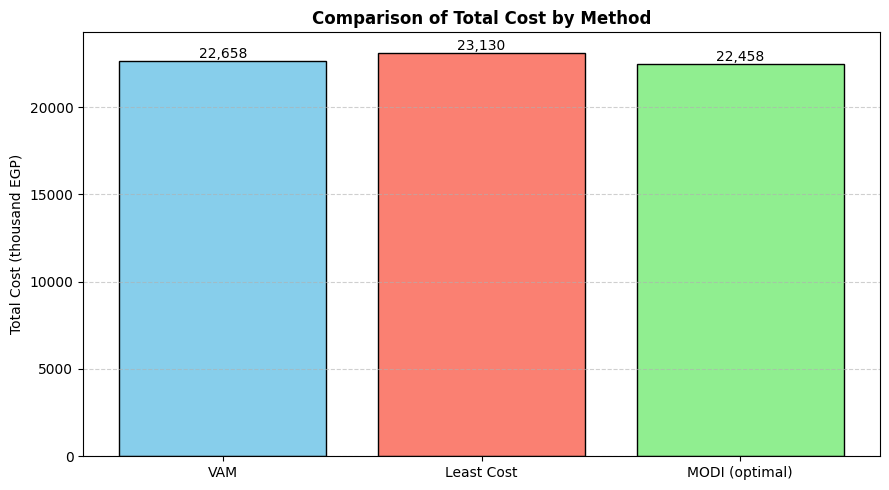

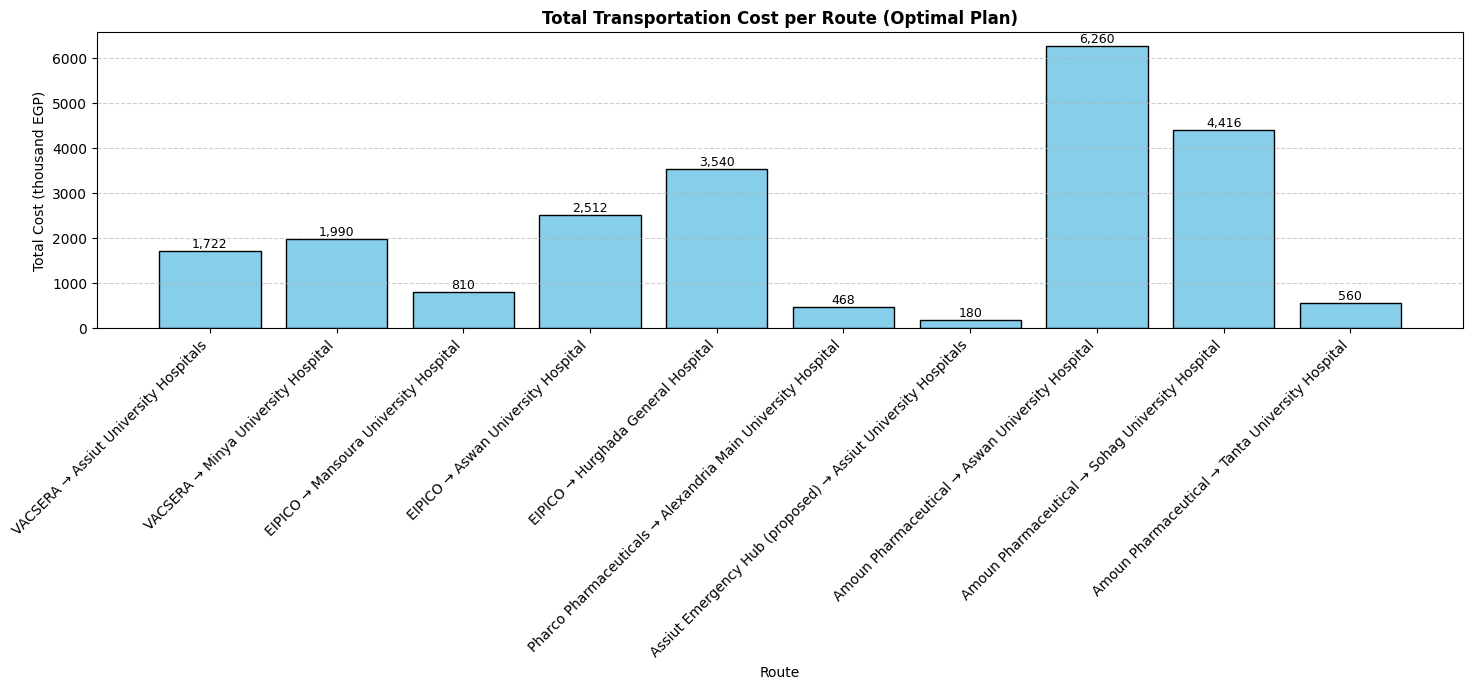

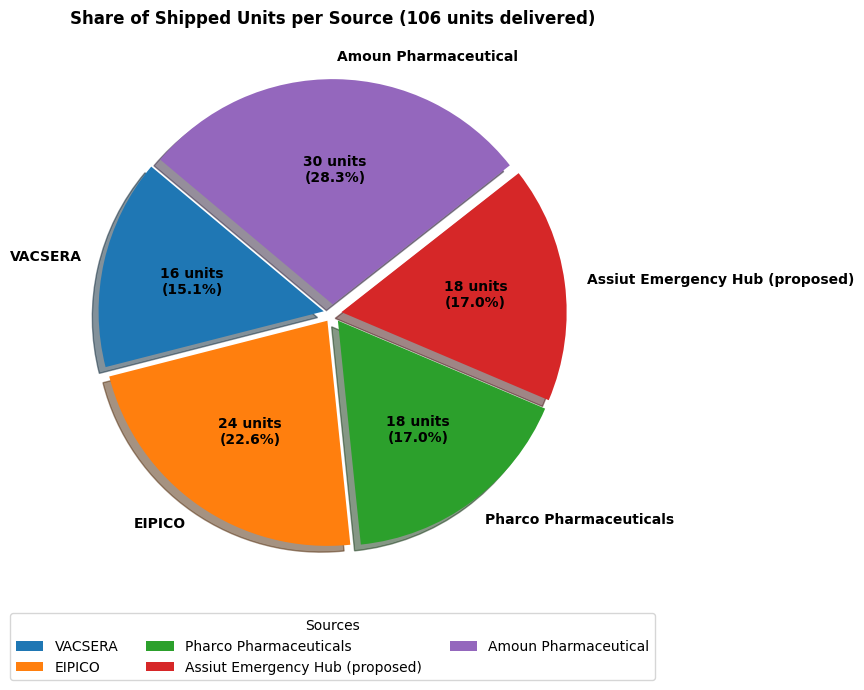

In [8]:
real_columns = [j for j, name in enumerate(destinations) if name != DUMMY_DEST]

routes = []
route_total_costs = []

for i, j in zip(*np.where(opt_alloc > 0)):
    if destinations[j] == DUMMY_DEST:
        continue
    routes.append(f"{sources[i]} → {destinations[j]}")
    route_total_costs.append(opt_alloc[i, j] * cost[i, j])


plt.figure(figsize=(9, 5))

values = [vam_cost, lcm_cost, opt_cost]

bars = plt.bar(
    ["VAM", "Least Cost", "MODI (optimal)"],
    values,
    color=["skyblue", "salmon", "lightgreen"],
    edgecolor="black"
)

plt.title("Comparison of Total Cost by Method", weight="bold")
plt.ylabel("Total Cost (thousand EGP)")
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 7))

plt.bar(routes, route_total_costs, color="skyblue", edgecolor="black")

plt.title("Total Transportation Cost per Route (Optimal Plan)", weight="bold")
plt.xlabel("Route")
plt.ylabel("Total Cost (thousand EGP)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.6)

for k, value in enumerate(route_total_costs):
    plt.text(k, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


shipped = opt_alloc[:, real_columns].sum(axis=1)

indices = [
    i for i, name in enumerate(sources)
    if name != DUMMY_SOURCE and shipped[i] > 0
]

labels = [sources[i] for i in indices]
values = [shipped[i] for i in indices]

def label_format(pct):
    units = round(pct * sum(values) / 100)
    return f"{units} units\n({pct:.1f}%)"

plt.figure(figsize=(10, 7))

plt.pie(
    values,
    labels=labels,
    autopct=label_format,
    startangle=140,
    explode=[0.04] * len(values),
    shadow=True,
    textprops={"fontsize": 10, "weight": "bold"}
)

plt.title(f"Share of Shipped Units per Source ({sum(values):.0f} units delivered)", weight="bold")
plt.legend(title="Sources", loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3)
plt.tight_layout()
plt.show()

### 4.3 Hub analysis

In [9]:
keep = [i for i, name in enumerate(raw_sources) if "proposed" not in name]

cost_nh, supply_nh, demand_nh, sources_nh, destinations_nh = balance_problem(
    raw_cost[keep, :],
    [raw_supply[i] for i in keep],
    raw_demand,
    [raw_sources[i] for i in keep],
    raw_destinations
)

vam_nh, _ = vogel_approximation(cost_nh, supply_nh, demand_nh)
opt_nh, _, _ = modi_method(cost_nh, vam_nh, show_steps=False)
check_solution("No-hub plan", opt_nh, supply_nh, demand_nh)

cost_without_hub = np.sum(opt_nh * cost_nh)

assert sources_nh[-1] == DUMMY_SOURCE
unmet = opt_nh[-1, :]

print("\n===== Hub analysis =====")
print(f"WITH the hub   : cost = {opt_cost:,.0f} thousand EGP | all {sum(raw_demand):.0f} units delivered")
print(f"WITHOUT the hub: cost = {cost_without_hub:,.0f} thousand EGP | {unmet.sum():.0f} units NOT delivered")
for j, name in enumerate(destinations_nh):
    if unmet[j] > 0:
        print(f"   short hospital: {name} ({unmet[j]:.0f} units)")
print(f"The hub saves {cost_without_hub - opt_cost:,.0f} thousand EGP and covers the whole demand.")

Added Unmet Demand: 8.0
No-hub plan: all checks passed

===== Hub analysis =====
WITH the hub   : cost = 22,458 thousand EGP | all 106 units delivered
WITHOUT the hub: cost = 22,932 thousand EGP | 8 units NOT delivered
   short hospital: Aswan University Hospital (8 units)
The hub saves 474 thousand EGP and covers the whole demand.


### 4.4 Summary table

In [10]:
summary = pd.DataFrame({
    "Method": ["Least Cost (LCM)", "Vogel (VAM)", "MODI (optimal)"],
    "Total cost (thousand EGP)": [lcm_cost, vam_cost, opt_cost],
})
summary["Above optimum"] = summary["Total cost (thousand EGP)"] - opt_cost
summary["Above optimum (%)"] = (summary["Above optimum"] / opt_cost * 100).round(2)

print(f"MODI pivots needed from VAM: {pivots}")
summary

MODI pivots needed from VAM: 2


,Method,Total cost (thousand EGP),Above optimum,Above optimum (%)
0,Least Cost (LCM),23130.0,672.0,2.99
1,Vogel (VAM),22658.0,200.0,0.89
2,MODI (optimal),22458.0,0.0,0.00
